In [25]:
from torch_geometric.datasets import TUDataset
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from dhg import Graph, Hypergraph
import dhg


In [76]:
# original_dataset = TUDataset(root='../data/', name="NCI1", use_node_attr=True)
original_dataset = TUDataset(root='../data/', name="MUTAG", use_node_attr=True)
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
# dataset = HGDataset(original_dataset, to_hg_func)
# in_channels = dataset.num_node_features
# out_channels = dataset.num_classes

In [77]:
graph_dat = original_dataset[0]

In [78]:
edge_list = graph_dat.edge_index.t() if 'edge_index' in graph_dat.keys() else None
num_vertices = graph_dat.num_nodes # if 'num_nodes' in graph_dat.keys() else None
node_features = graph_dat.x if 'x' in graph_dat.keys() else None
labels = graph_dat.y if 'y' in graph_dat.keys() else None

G = Graph(num_vertices, edge_list)
HG1 = Hypergraph.from_graph_kHop(G, 1)

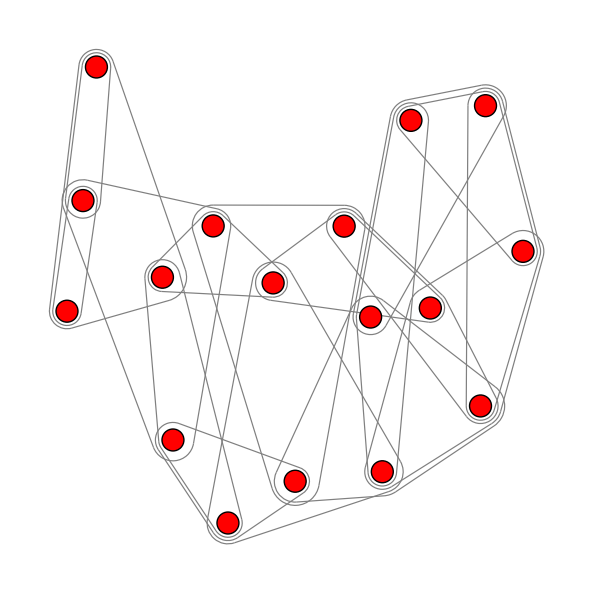

In [79]:
HG1.draw()

In [74]:
HG1

Hypergraph(num_v=21, num_e=21)

In [36]:
hg

Hypergraph(num_v=5, num_e=10)

Graph with 5 nodes and 1 edges
Hypergraph(num_v=5, num_e=4)


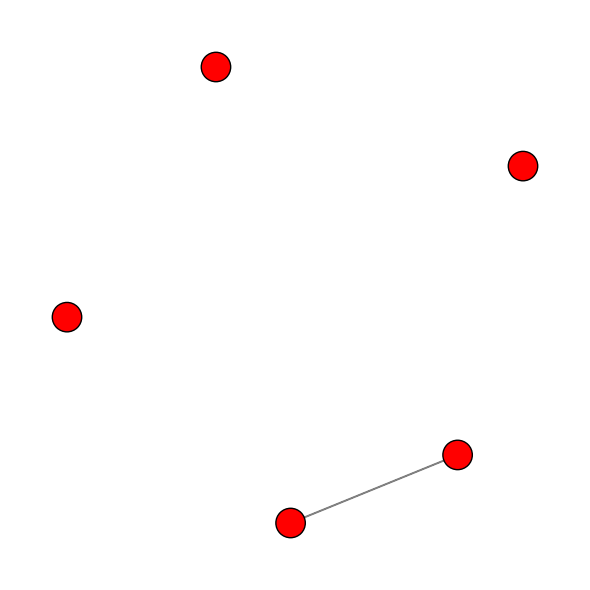

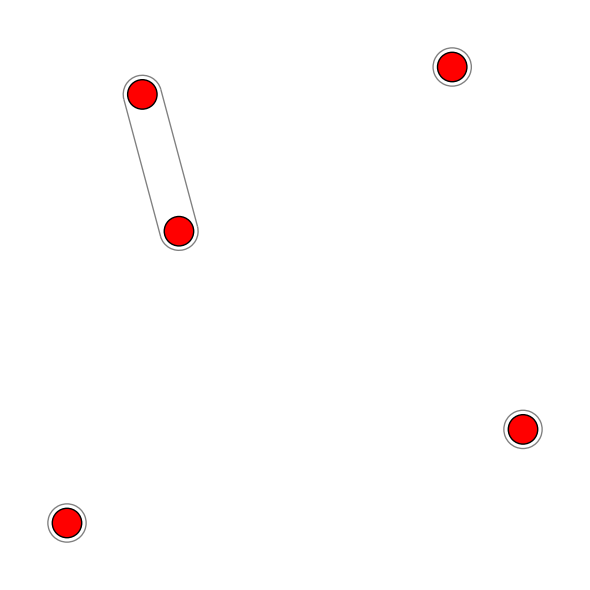

In [99]:
import networkx as nx

# Generate a random graph with 10 nodes and probability of edge creation 0.5
graph = nx.gnp_random_graph(5, 0.1)

# Print the graph
print(graph)
G = Graph.from_adj_list(len(graph.nodes), graph.edges)

hg = Hypergraph.from_graph_kHop(G, 1)
print(hg)

G.draw()
hg.draw()


Graph with 5 nodes and 4 edges
Hypergraph(num_v=5, num_e=4)


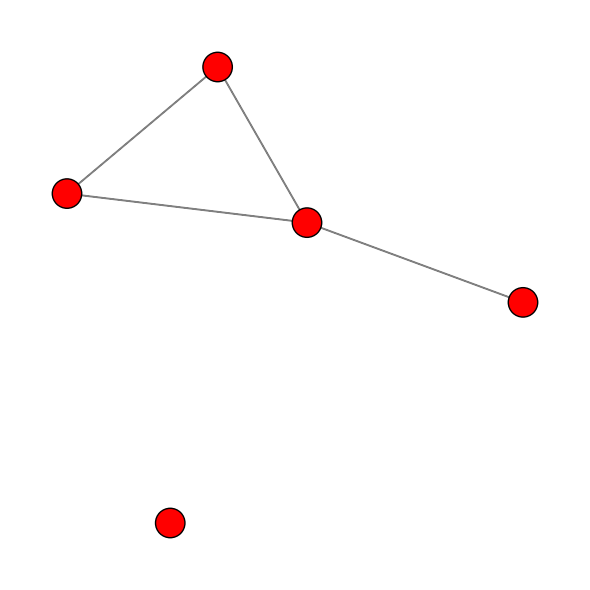

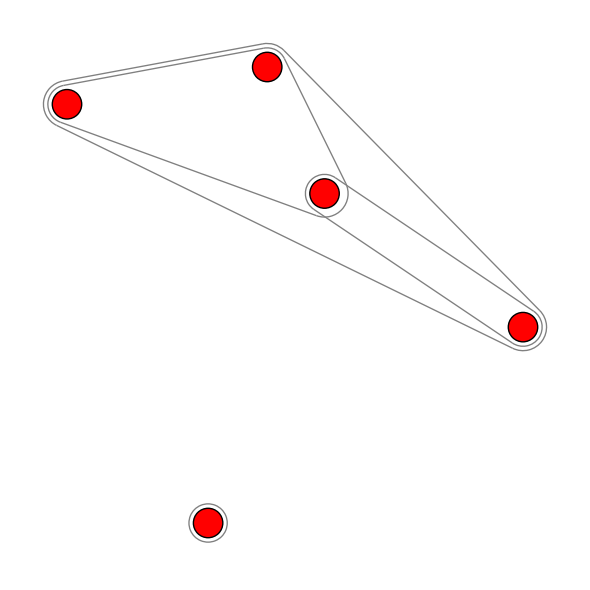

In [108]:
import networkx as nx

# Generate a random graph with 10 nodes and probability of edge creation 0.5
graph = nx.gnp_random_graph(5, 0.5)

# Print the graph
print(graph)
G = Graph.from_adj_list(len(graph.nodes), graph.edges)

hg = Hypergraph.from_graph_kHop(G, 1)
print(hg)

G.draw()
hg.draw()


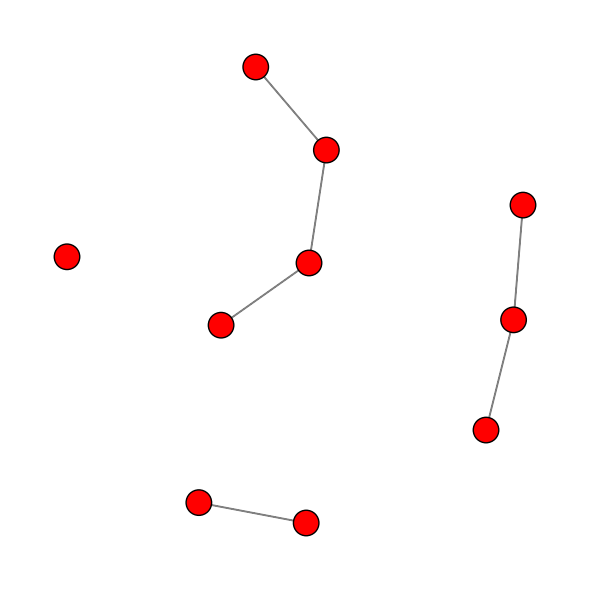

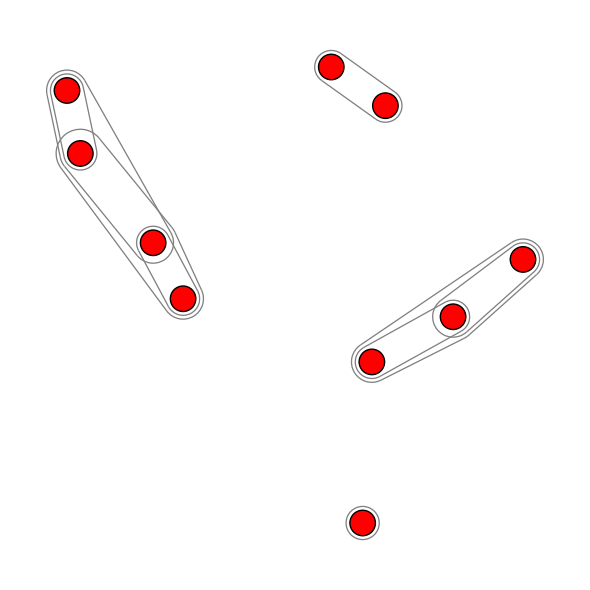

Graph with 3 nodes and 3 edges
Hypergraph(num_v=3, num_e=1)


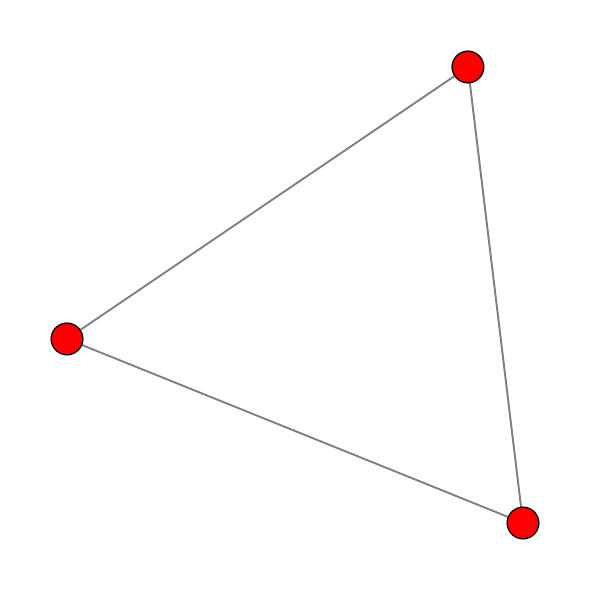

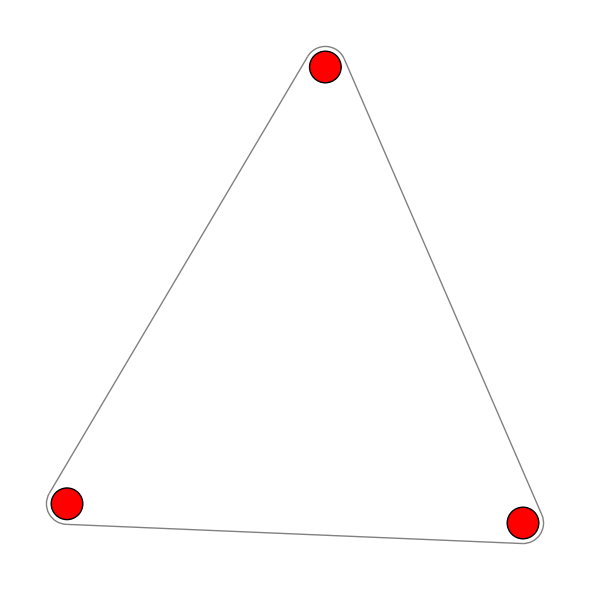

In [109]:
import networkx as nx

# Generate a random graph with 10 nodes and probability of edge creation 0.5
graph = nx.complete_graph(3)

# Print the graph
print(graph)
G = Graph.from_adj_list(len(graph.nodes), graph.edges)

hg = Hypergraph.from_graph_kHop(G, 1)
print(hg)

G.draw()
hg.draw()
